# 6. 인물사진을 만들어 보자 [프로젝트: 인물 모드 문제점 찾기]

* Step 1. 인물모드 직접 해 보기
* Step 2. 사진에서 문제점 찾기
* Step 3. 해결 방법을 제안해 보기

In [235]:
# 라이브러리 버전 확인
# importlib: 사용자가 파이썬의 import 시스템과 상호작용하기 위한 API를 제공하는 내장 라이브러리
# 사용자는 import 함수의 구현 내용과, 실행에 필요한 하위 함수들을 이용해 필요에 맞는 임포터를 직접 구현하거나 임포트 관련 기능들을 자유롭게 사용할 수 있음
# importlib.metadata: 설치된 패키지 메타 데이터에 대한 접근을 제공하는 라이브러리.
# 해당 코드 블럭에서는 importlib.metadata 안에 있는 version() 함수를 이용하여 pixellib 라이브러리의 버전을 확인

from importlib.metadata import version
import cv2
import pixellib

print(cv2.__version__)
print(version('pixellib'))

4.5.3
0.7.1


## Step 1. 인물모드 직접 해 보기

* 여러분의 셀카를 이용해서 오늘 배운 내용을 수행해 봅시다. 아래와 같은 이미지를 얻어야 합니다. 최소 3장 이상의 인물모드 사진을 만들어 봅시다.
* 인물이 주인공이 아닌, 귀여운 고양이에 대한 아웃포커싱 사진도 만들어 볼 수 있을 것입니다. 시맨틱 세그멘테이션 스텝에서 힌트를 찾아봅시다.
* 배경을 blur하는 인물모드 사진이 아니라 배경사진을 다른 이미지로 교체하는 크로마키 배경 합성을 시도해 볼 수도 있을 것입니다. 여러분만의 환상적인 사진을 만들어 보면 어떨까요?

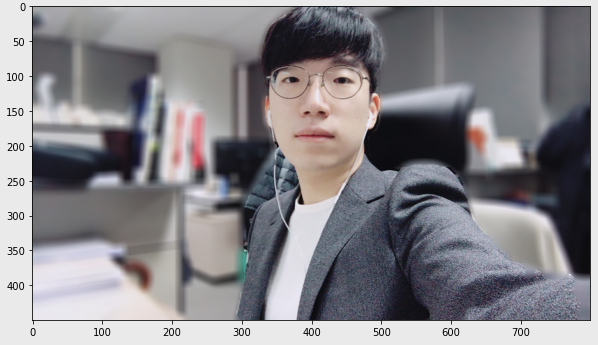

### 준비물
실습을 위한 폴더를 만들고, 데이터 폴더를 연결한다.
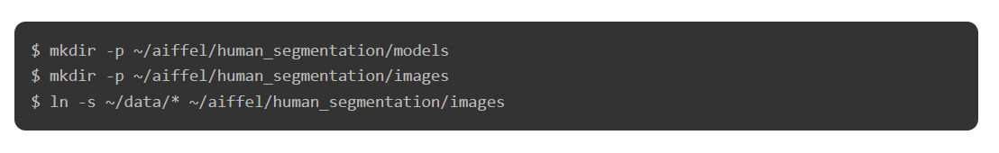

* human_segmentation => object_segmentation

## 셸로우 포커스 만들기 (1) 사진을 준비하자
---
#### 하나의 카메라로 셸로우 포커스(shallow focus)를 만드는 방법


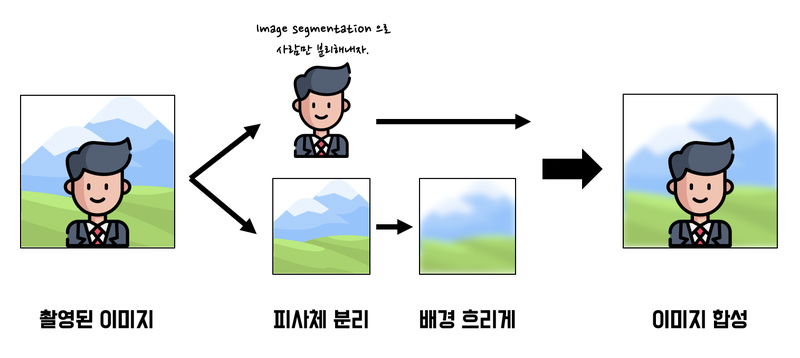

두 개의 렌즈가 맡은 역할을 하나의 렌즈에서 구현해야 합니다. 이미지 세그멘테이션(image segmentation) 기술을 이용하면 하나의 이미지에서 배경과 사람을 분리할 수 있습니다. 분리된 배경을 블러(blur) 처리 후 사람 이미지와 다시 합하면 아웃포커싱 효과를 적용한 인물 사진을 얻을 수 있습니다.

따라서 우리는 다음과 같은 후가공으로 '인물사진 모드'인 사진을 만들 겁니다.

1. 배경이 있는 셀카를 촬영합니다. (배경과 사람의 거리가 약간 멀리 있으면 좋습니다.)
2. 시맨틱 세그멘테이션(Semantic segmentation)으로 피사체(사람)와 배경을 분리합니다.
3. 블러링(blurring) 기술로 배경을 흐리게 합니다.
4. 피사체를 배경의 원래 위치에 합성합니다.

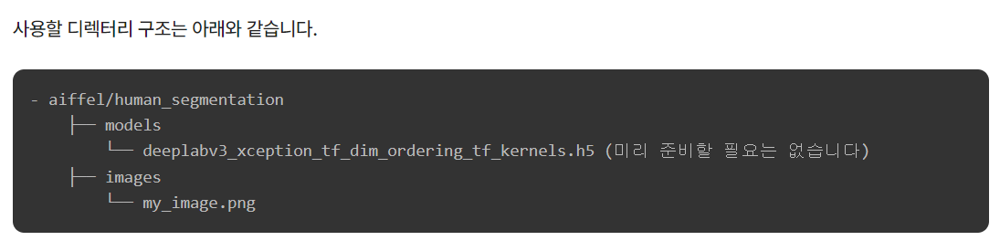
* human_segmentation => object_segmentation

In [236]:
# 라이브러리 불러오기
# os: Operating System의 줄임말로, 운영체제에서 제공되는 여러 기능을 파이썬에서 사용할 수 있도록 함 (Ex. 디렉토리 경로 이동, 시스템 환경 변수 가져오기 등)
# urllib: URL 작업을 위한 여러 모듈을 모은 패키지. (Ex. urllib.request, urllib.parse, ...)
# cv2: OpenCV 라이브러리로, 실시간 컴퓨터 비전을 목적으로 한 프로그래밍 라이브러리
# numpy(NumPy): 행렬이나 대규모 다차원 배열을 쉽게 처리할 수 있도록 지원하는 라이브러리. 데이터 구조 외에도 수치 계산을 위해 효율적으로 구현된 기능을 제공
# pixellib: 이미지 및 비디오 segmentation을 수행하기 위한 라이브러리. 
# pixellib.semantic: segmentation 기법 중, semantic segmentation을 쉽게 사용할 수 있도록 만든 라이브러리
# matplotlib: 파이썬 프로그래밍 언어 및 수학적 확장 NumPy 라이브러리를 활용한 플로팅 라이브러리로, 데이터 시각화 도구
import os
import urllib
import cv2
import numpy as np
from pixellib.semantic import semantic_segmentation
from matplotlib import pyplot as plt

print('슝=3')

슝=3


* urllib는 웹에서 데이터를 다운로드할 때 사용한다.
* cv2는 OpenCV 라이브러리로 이미지를 처리하기 위해 필요하다.
* pixellib는 시맨틱 세그멘테이션을 편하게 사용할 수 있는 라이브러리이다. 아직 시맨틱 세그멘테이션 모델을 직접 만들기에는 어려우니 이번에는 준비된 모델을 사용만 해보자.
* 이제 라이브러리에 대해 이해가 되었으니 시작해 보자.

준비한 이미지를 읽는다.

In [237]:
# os 모듈에 있는 getenv() 함수를 이용하여 읽고싶은 파일의 경로를 file_path에 저장
# 준비한 이미지 파일의 경로를 이용하여, 이미지 파일을 읽음
img_path1 = os.getenv('HOME')+'/aiffel/object_segmentation/images/me1.jpg'
img_path2 = os.getenv('HOME')+'/aiffel/object_segmentation/images/me2.jpg'
img_path3 = os.getenv('HOME')+'/aiffel/object_segmentation/images/me3.jpg'
img_path4 = os.getenv('HOME')+'/aiffel/object_segmentation/images/itsme.jpg'
img_path_gabi = os.getenv('HOME')+'/aiffel/object_segmentation/images/gabi1.jpg'

# cv2.imread(경로): 경로에 해당하는 이미지 파일을 읽어서 변수에 저장
img_orig1 = cv2.imread(img_path1)
img_orig2 = cv2.imread(img_path2) 
img_orig3 = cv2.imread(img_path3) 
img_orig4 = cv2.imread(img_path4) 
img_orig_gabi = cv2.imread(img_path_gabi) 

#### 이미지 전처리를 진행하자.

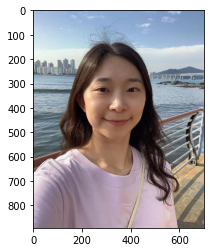

In [238]:
from PIL import Image

# 이미지 전처리 함수
def resize_image(input_image_path, output_image_path, new_width, new_height):
    img = Image.open(input_image_path)
    resized_img = img.resize((new_width, new_height), Image.ANTIALIAS)
    resized_img.save(output_image_path)

# 사용 예시
input_image_path = img_path1 
output_image_path = img_path1 
new_width = 700
new_height = 892

resize_image(input_image_path, output_image_path, new_width, new_height)

img_orig1 = cv2.imread(img_path1)

plt.imshow(cv2.cvtColor(img_orig1, cv2.COLOR_BGR2RGB)) # 이미지 색상 채널을 변경 (BGR 형식을 RGB 형식으로 변경)
plt.show() # 저장된 데이터를 이미지의 형식으로 표시

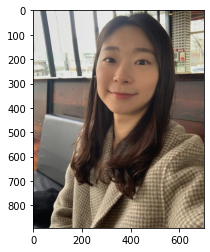

In [239]:
# 나머지 사진들도 전처리를 진행

resize_image(img_path2, img_path2, 700, 892)

img_orig2 = cv2.imread(img_path2)

plt.imshow(cv2.cvtColor(img_orig2, cv2.COLOR_BGR2RGB)) # 이미지 색상 채널을 변경 (BGR 형식을 RGB 형식으로 변경)
plt.show() # 저장된 데이터를 이미지의 형식으로 표시

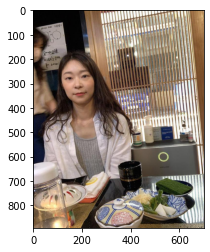

In [240]:
# 나머지 사진들도 전처리를 진행

resize_image(img_path3, img_path3, 700, 892)

img_orig3 = cv2.imread(img_path3)

plt.imshow(cv2.cvtColor(img_orig3, cv2.COLOR_BGR2RGB)) # 이미지 색상 채널을 변경 (BGR 형식을 RGB 형식으로 변경)
plt.show() # 저장된 데이터를 이미지의 형식으로 표시

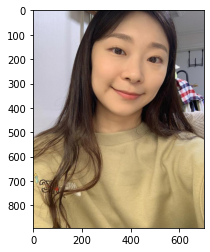

In [241]:
# 나머지 사진들도 전처리를 진행

resize_image(img_path4, img_path4, 700, 892)

img_orig4 = cv2.imread(img_path4)

plt.imshow(cv2.cvtColor(img_orig4, cv2.COLOR_BGR2RGB)) # 이미지 색상 채널을 변경 (BGR 형식을 RGB 형식으로 변경)
plt.show() # 저장된 데이터를 이미지의 형식으로 표시

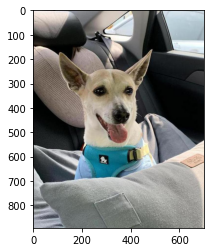

In [242]:
# 나머지 사진들도 전처리를 진행

resize_image(img_path_gabi, img_path_gabi, 700, 892)

img_orig_gabi = cv2.imread(img_path_gabi)

plt.imshow(cv2.cvtColor(img_orig_gabi, cv2.COLOR_BGR2RGB)) # 이미지 색상 채널을 변경 (BGR 형식을 RGB 형식으로 변경)
plt.show() # 저장된 데이터를 이미지의 형식으로 표시

## 셸로우 포커스 만들기 (2) 세그멘테이션으로 사람 분리하기
---
배경에만 렌즈 흐림 효과를 주기 위해서 그림과 같이 이미지에서 사람과 피사체를 분리해야 한다. 흔히 포토샵으로 '누끼 따기'라는 것이 바로 이런 작업을 말한다. 인물 사진에서 배경만 다르게 편집하려는 용도로 흔히 하는 작업이다.
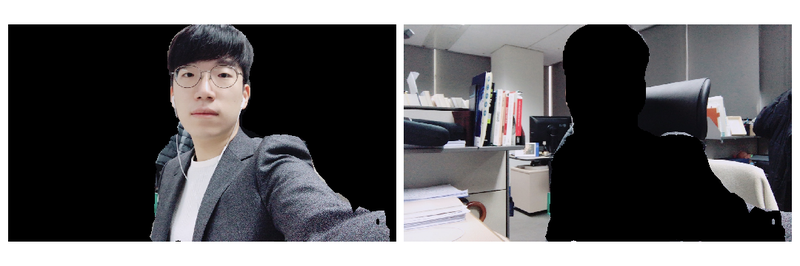

PixelLib에서 제공해 주는 모델을 다운로드한다.

### 세그멘테이션(Segmentation)이 뭘까?
---
이미지에서 픽셀 단위로 관심 객체를 추출하는 방법을 이미지 세그멘테이션(image segmentation) 이라고 한다. 이미지 세그멘테이션은 모든 픽셀에 라벨(label)을 할당하고, 라벨이 같은 객체들은 "공통적인 특징"을 가진다고 가정한다. 이때 공통 특징은 물리적 의미가 없을 수도 있다. 픽셀이 비슷하게 생겼다는 사실은 인식하지만, 우리가 아는 것처럼 실제 물체 단위로 인식하지 않을 수 있는 것이다. 물론 세그멘테이션에는 여러 가지 세부 태스크가 있으며, 태스크에 따라 다양한 기준으로 객체를 추출한다.

#### 시맨틱 세그멘테이션(semantic segmentation)이란?

세그멘테이션 중에서도 특히, 우리가 인식하는 세계처럼 물리적 의미 단위로 인식하는 세그멘테이션을 시맨틱 세그멘테이션 이라고 한다. 쉽게 설명하면 이미지에서 픽셀을 사람, 자동차, 비행기 등의 물리적 단위로 분류(classification)하는 방법이라고 이해하시면 된다. 오늘 다룰 세그멘테이션 방법이기도 하다.

#### 인스턴스 세그멘테이션(Instance segmentation)이란?
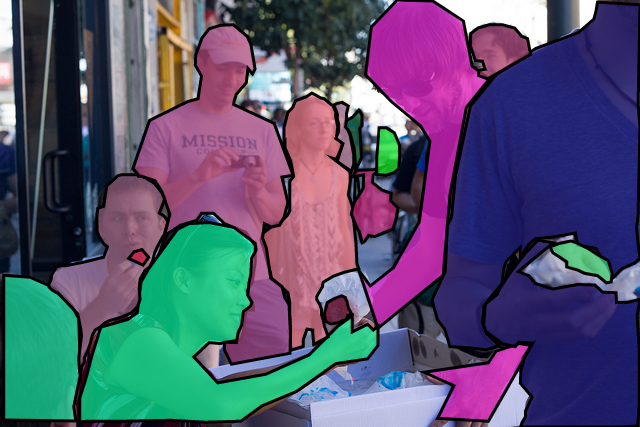

시맨틱 세그멘테이션은 '사람'이라는 추상적인 정보를 이미지에서 추출해 내는 방법이다. 그래서 사람이 누구인지 관계없이 같은 라벨로 표현이 된다.

더 나아가서 인스턴스 세그멘테이션은 사람 개개인별로 다른 라벨을 가지게 한다. 여러 사람이 한 이미지에 등장할 때 각 객체를 분할해서 인식하자는 것이 목표이다.

**Q. 인스턴스 세그멘테이션 데이터셋과 라벨이 존재하면 시맨틱 세그멘테이션을 학습시킬 수 있을까요?**

인스턴스의 id 뿐만이 아닌 클래스 라벨이 존재해야 시맨틱 세그멘테이션으로 학습이 가능합니다. 근본적으로는 다른 개념이지만 대부분의 데이터셋은 인스턴스 라벨이 있는 경우 클래스 라벨도 함께 존재합니다.

-> 더 자세하게 설명하자면,

인스턴스 세그멘테이션 데이터셋은 이미지 내의 개별 객체들을 분할하고, 각 객체에 대한 고유한 ID를 할당하는 작업을 의미합니다. 예를 들어, 여러 사람이 있는 이미지에서 각 사람마다 다른 ID가 할당된 분할된 영역을 볼 수 있습니다.

반면에 시맨틱 세그멘테이션은 이미지를 클래스별로 분할하는 작업입니다. 각 픽셀에 대해 해당하는 클래스에 라벨을 지정하는 것입니다. 예를 들어, 분할된 이미지 내에서 모든 사람 영역에 "사람"이라는 라벨을 할당하는 것이 시맨틱 세그멘테이션입니다.

인스턴스 세그멘테이션 데이터셋은 객체를 분할하고 각각의 ID를 할당하는데 중점을 두며, 클래스 정보에 대한 상세한 라벨을 가지고 있지 않을 수 있습니다. 그러나 대부분의 경우, 인스턴스 세그멘테이션 데이터셋에는 클래스 라벨 정보도 함께 제공됩니다. 예를 들어, "사람"이라는 클래스에 해당하는 객체에 대해 각각의 고유한 ID가 부여되는 식으로 정보가 구성될 수 있습니다.

따라서, 시맨틱 세그멘테이션을 학습시키기 위해서는 클래스 라벨에 대한 정보가 필요합니다. 보통 인스턴스 세그멘테이션 데이터셋에는 객체의 ID 뿐만 아니라 해당 객체가 어떤 클래스에 속하는지를 나타내는 클래스 라벨 정보도 포함되어 있어야 합니다. 이 정보를 활용하여 모델은 픽셀 단위로 클래스를 분류하는 시맨틱 세그멘테이션을 학습할 수 있게 됩니다.

### 딥러닝에 기반한 방법 이전에는 어떻게 이미지 세그멘테이션을 했을까?
---
**워터쉐드 세그멘테이션(watershed segmentation)**

이미지에서 영역을 분할하는 가장 간단한 방법은 물체의 '경계'를 나누는 것이다. 그럼 경계는 어떻게 나눌 수 있을까?

이미지는 그레이스케일(grayscale)로 변환하면 0~255의 값을 가진다. 픽셀 값을 이용해서 각 위치의 높고 낮음을 구분할 수 있다. 낮은 부분부터 서서히 '물'을 채워 나간다고 생각하면 각 영역에서 점점 물이 차오르다가 넘치는 시점이 생기게 된다. 그 부분을 경계선으로 만들면 물체를 서로 구분할 수 있게 된다.

자세한 내용은 opencv-python tutorial을 참고하면 된다.

https://opencv-python.readthedocs.io/en/latest/doc/27.imageWaterShed/imageWaterShed.html

## 셸로우 포커스 만들기 (3) 시맨틱 세그멘테이션 다뤄보기
---
본격적으로 세그멘테이션을 다루어 보겠다. 세그멘테이션 문제에는 FCN, SegNet, U-Net 등 많은 모델이 사용된다. 오늘은 그중에서 DeepLab이라는 세그멘테이션 모델을 이용해 볼 것이다. DeepLab 알고리즘(DeepLab v3+)은 세그멘테이션 모델 중에서도 성능이 매우 좋아 최근까지도 많이 사용되고 있다.

오늘은 네트워크에 대한 자세한 설명보다 세그멘테이션의 활용 방법 위주로 다루겠다.

DeepLab에 대한 자세한 설명은 아래 링크를 참고하자.

https://bloglunit.wordpress.com/2018/07/02/deeplab-v3-encoder-decoder-with-atrous-separable-convolution-for-semantic-image-segmentation/

**Q. DeepLab에서 atrous convolution을 사용한 이유가 무엇인가요?**

eceptive field를 넓게 사용하기 위해 사용합니다. (적은 파라미터로 필터가 더 넓은 영역을 보게 하기 위해)

**Q. Depthwise separable convolution은 어디서 처음 사용한 것 일까요? 왜 이 구조가 효율적일까요?**

Xception 에서 제안되었습니다. 3x3 conv layer 의 receptive field를 1/9 수준의 파라미터로 구현할 수 있기 때문에 효율적입니다.

Xception 더 알아보기: https://arxiv.org/abs/1610.02357

DeepLab 모델을 준비하겠다. 아까 준비한 PixelLib를 이용하면 편하게 사용할 수 있다.


PixelLib: https://github.com/ayoolaolafenwa/PixelLibhttps://github.com/ayoolaolafenwa/PixelLibhttps://github.com/ayoolaolafenwa/PixelLibhttps://github.com/ayoolaolafenwa/PixelLib

In [243]:
# 저장할 파일 이름을 결정합니다
# 1. os.getenv(x)함수는 환경 변수x의 값을 포함하는 문자열 변수를 반환합니다. model_dir 에 "/aiffel/human_segmentation/models" 저장
# 2. #os.path.join(a, b)는 경로를 병합하여 새 경로 생성 model_file 에 "/aiffel/aiffel/human_segmentation/models/deeplabv3_xception_tf_dim_ordering_tf_kernels.h5" 저장
# 1
model_dir = os.getenv('HOME')+'/aiffel/object_segmentation/models' 
# 2
model_file = os.path.join(model_dir, 'deeplabv3_xception_tf_dim_ordering_tf_kernels.h5') 

# PixelLib가 제공하는 모델의 url입니다
model_url = 'https://github.com/ayoolaolafenwa/PixelLib/releases/download/1.1/deeplabv3_xception_tf_dim_ordering_tf_kernels.h5' 

# 다운로드를 시작합니다
urllib.request.urlretrieve(model_url, model_file) # urllib 패키지 내에 있는 request 모듈의 urlretrieve 함수를 이용해서 model_url에 있는 파일을 다운로드 해서 model_file 파일명으로 저장

('/aiffel/aiffel/object_segmentation/models/deeplabv3_xception_tf_dim_ordering_tf_kernels.h5',
 <http.client.HTTPMessage at 0x7f3aba7eb520>)

그다음 다운로드한 모델을 이용해 PixelLib로 우리가 사용할 세그멘테이션 모델을 생성한다.

In [244]:
model = semantic_segmentation() #PixelLib 라이브러리 에서 가져온 클래스를 가져와서 semantic segmentation을 수행하는 클래스 인스턴스를 만듬
model.load_pascalvoc_model(model_file) # pascal voc에 대해 훈련된 예외 모델(model_file)을 로드하는 함수를 호출

모델에 이미지를 입력해 보자.

In [245]:
segvalues, output = model.segmentAsPascalvoc(img_path1) # segmentAsPascalvoc()함수를 호출 하여 입력된 이미지를 분할, 분할 출력의 배열을 가져옴, 분할은 pacalvoc 데이터로 학습된 모델을 이용                                                       

segmentAsPascalvoc라는 함수 이름에서 세그멘테이션 모델에 대한 힌트를 얻을 수 있다. PASCAL VOC 데이터로 학습된 모델을 이용한다는 의미이다. 모델마다 학습시킨 데이터에 따라 결괏값이 달라지므로 어떤 데이터를 학습시켰는지 확인하는 것은 매우 중요하다.

http://host.robots.ox.ac.uk/pascal/VOC/

PASCAL VOC 데이터의 라벨 종류는 아래와 같다.

In [246]:
#pascalvoc 데이터의 라벨종류
LABEL_NAMES = [
    'background', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus',
    'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike',
    'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tv'
]
len(LABEL_NAMES)

21

background를 제외하면 20개의 클래스가 있다. 따라서 20 의 의미는 tv 가 되겠다! 0부터 시작하기 때문이다.

이 중에서 사람(person) 라벨, 즉 15를 가진 영역만 검출해 내고 싶다. 이제 사람만 어떻게 추출할 수 있을지 알아보자.

아까 모델에서 나온 출력값을 살짝 살펴보자.

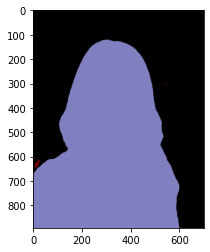

In [247]:
#segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 output을 matplotlib을 이용해 출력
plt.imshow(output)
plt.show()

In [248]:
segvalues # segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 배열값을 출력

{'class_ids': array([ 0,  4, 15]),
 'masks': array([[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [ True,  True,  True, ..., False, False, False],
        [ True,  True,  True, ..., False, False, False],
        [ True,  True,  True, ..., False, False, False]])}

* output - 입력된 이미지를 분할한 뒤 나온 결과값
* segvalues - 입력된 이미지를 분할한 뒤 나온 결과값 중 배열값

In [249]:
#segvalues에 있는 class_ids를 담겨있는 값을 통해 pacalvoc에 담겨있는 라벨을 출력
for class_id in segvalues['class_ids']:
    print(LABEL_NAMES[class_id])

background
boat
person


output에는 세그멘테이션이 된 결과가 각각 다른 색상으로 담겨 있다. segvalues에는 class_ids와 masks가 있다. class_ids를 통해 어떤 물체가 담겨 있는지 알 수 있다!

이제 물체마다 output에 어떤 색상으로 나타나 있는지만 알아내면 될 것 같다.

In [250]:
# 아래 코드를 이해하지 않아도 좋습니다
# PixelLib에서 그대로 가져온 코드입니다
# 주목해야 할 것은 생상 코드 결과물이예요!

#컬러맵 만들기 
colormap = np.zeros((256, 3), dtype = int)
ind = np.arange(256, dtype=int)

for shift in reversed(range(8)):
    for channel in range(3):
        colormap[:, channel] |= ((ind >> channel) & 1) << shift
    ind >>= 3

colormap[:20] #생성한 20개의 컬러맵 출력

array([[  0,   0,   0],
       [128,   0,   0],
       [  0, 128,   0],
       [128, 128,   0],
       [  0,   0, 128],
       [128,   0, 128],
       [  0, 128, 128],
       [128, 128, 128],
       [ 64,   0,   0],
       [192,   0,   0],
       [ 64, 128,   0],
       [192, 128,   0],
       [ 64,   0, 128],
       [192,   0, 128],
       [ 64, 128, 128],
       [192, 128, 128],
       [  0,  64,   0],
       [128,  64,   0],
       [  0, 192,   0],
       [128, 192,   0]])

PixelLib에 따르면 위와 같은 색을 사용했다고 한다. 그럼 사람을 나타내는 15번째 색상은 무엇일까?

In [251]:
colormap[15] #컬러맵 15에 해당하는 배열 출력 (pacalvoc에 LABEL_NAMES 15번째인 사람)

array([192, 128, 128])

사람 외에도 다른 물체를 찾아내고 싶다면 colormap[class_id]처럼 찾아낼 수 있겠다,

여기서 주의할 것은 output 이미지가 BGR 순서로 채널 배치가 되어 있다는 점이다. colormap은 RGB 순서이다.

그러니 우리가 추출해야 하는 색상 값은 순서를 아래처럼 바꿔 줘야 한다.

In [252]:
seg_color = (128,128,192) # 색상순서 변경 - colormap의 배열은 RGB 순이며 output의 배열은 BGR 순서로 채널 배치가 되어 있어서

이제 seg_color로만 이루어진 마스크를 만들어 보자.

In [253]:
# output 형태 확인
output.shape # output 배열은 모델이 분할한 결과로, 각 픽셀에 대한 색상 정보를 담고 있다.

(892, 700, 3)

(892, 700)


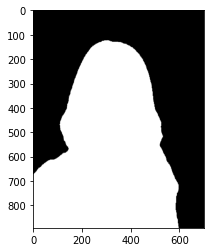

In [254]:
# output의 픽셀 별로 색상이 seg_color와 같다면 1(True), 다르다면 0(False)이 됩니다
# seg_color 값이 person을 값이 므로 사람이 있는 위치를 제외하고는 gray로 출력
# cmap 값을 변경하면 다른 색상으로 확인이 가능함
seg_map = np.all(output==seg_color, axis=-1) # output과 seg_color를 비교하여 모든 채널에 대해 같은 색상인지를 확인한다. 
                                             # axis=-1은 마지막 차원(컬러 채널)을 기준으로 비교하라는 의미한다.
print(seg_map.shape) 
plt.imshow(seg_map, cmap='gray') # cmap 파라미터를 설정하면 데이터의 값을 어떤 색상으로 나타낼지를 결정할 수 있다. 
                                 # 예를 들어, 'gray'로 설정하면 흑백 이미지처럼 보일 것이고, 'viridis', 'jet', 'hot' 등 다양한 컬러맵을 적용하여 데이터를 다양한 색상으로 표현한다.
                                 # seg_map의 True(1)는 흰색, False(0)는 검은색으로 표시된다.
plt.show()

3채널 가졌던 원본과는 다르게 채널 정보가 사라졌다.

이제 아래처럼 물체가 있는 위치는 1(True), 그 외에는 0(False)인 배열이 되었다.
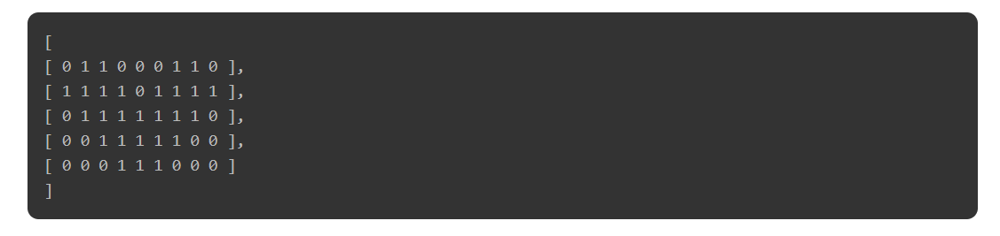
원래 이미지와 겹쳐 보면 세그멘테이션이 얼마나 잘 되었는지 알아보기 쉬울 것 같다.

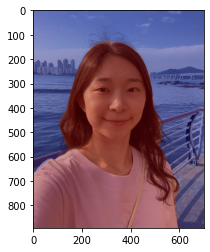

In [255]:
# 원본이미지를 img_show에 할당한뒤 이미지 사람이 있는 위치와 배경을 분리해서 표현한 color_mask 를 만든뒤 두 이미지를 합쳐서 출력
img_show = img_orig1.copy() # 원본 이미지를 수정하지 않고 복사본을 사용하기 img_show에 복자

# True과 False인 값을 각각 255과 0으로 바꿔줍니다
img_mask = seg_map.astype(np.uint8) * 255 # True는 사람 위치를 나타내며 255(흰색), False는 배경을 나타내며 0(검은색)
                                          # np.uint8 - 부호 없는 8비트 정수(unsigned 8-bit integer)
# 255와 0을 적당한 색상으로 바꿔봅니다 (색상 마스크 만들기)
color_mask = cv2.applyColorMap(img_mask, cv2.COLORMAP_JET) # img_mask에 적당한 컬러 맵을 적용하여 색상 마스크(color_mask)를 만든다.
                                                           # cv2.COLORMAP_JET을 사용하여 마스크 이미지의 값을 적절한 색상으로 매핑

# 원본 이미지와 마스크를 적당히 합쳐봅니다
# 0.6과 0.4는 두 이미지를 섞는 비율입니다.
img_show = cv2.addWeighted(img_show, 0.6, color_mask, 0.4, 0.0) # img_show와 color_mask를 일정 비율로 합성하여 최종적인 시각화 이미지를 만듦
                                                                # cv2.addWeighted() 함수를 사용하여 두 이미지를 섞어서 출력 이미지를 생성
                                                                # 첫 번째 이미지는 img_show로, 두 번째 이미지는 color_mask로 설정되었으며, 0.6과 0.4는 각 이미지의 가중치를 나타냄
plt.imshow(cv2.cvtColor(img_show, cv2.COLOR_BGR2RGB)) # img_show는 원본 이미지와 사람의 위치를 강조한 컬러 마스크를 합친 이미지
plt.show()

#### np.uint8:

np.uint8은 NumPy 라이브러리에서 제공하는 데이터 타입 중 하나입니다. 이는 부호 없는 8비트 정수(unsigned 8-bit integer)를 나타냅니다.

unsigned: 부호 없는 데이터 타입을 의미합니다. 즉, 양수만 표현할 수 있고 음수를 나타내지 않습니다.
8-bit integer: 8비트(한 바이트)로 값을 표현하는 정수형 데이터 타입입니다. 0부터 255까지의 값을 표현할 수 있습니다.
np.uint8은 주로 이미지 처리와 관련된 작업에서 픽셀 값을 나타내기 위해 사용됩니다. 컬러 이미지에서 각 채널(RGB)의 픽셀 값을 나타내거나, 흑백 이미지의 픽셀 값을 표현하는 데 사용됩니다. 이는 8비트로 표현되기 때문에 각 픽셀은 0부터 255까지의 정수 값으로 표현될 수 있습니다. 0은 어두운 색이고, 255는 밝은 색을 나타냅니다.

cv2.cvtColor():

cv2.cvtColor()는 OpenCV 라이브러리에서 제공하는 이미지 컬러 변환 함수입니다. 이 함수는 이미지의 컬러 스페이스를 변경하거나 변환하는 데 사용됩니다.

주로 이미지의 컬러 스페이스를 변경하거나 다른 컬러 스페이스로 변환할 때 사용됩니다. 예를 들어, BGR에서 RGB로, 또는 RGB에서 Grayscale로 변환하는 등의 작업에 활용됩니다.

이 함수는 아래와 같은 매개변수를 받습니다:

src: 변환할 이미지 데이터입니다.
code: 변환할 컬러 스페이스를 지정하는 상수입니다. 예를 들어, cv2.COLOR_BGR2RGB, cv2.COLOR_RGB2GRAY 등의 상수를 사용하여 컬러 스페이스를 지정할 수 있습니다.
cv2.cvtColor() 함수는 이러한 매개변수를 받아 이미지의 컬러 스페이스를 변환하고 변환된 이미지 데이터를 반환합니다. 이 함수를 통해 이미지를 원하는 컬러 스페이스로 변환하여 다양한 이미지 처리 및 분석 작업에 활용할 수 있습니다.

## 셸로우 포커스 만들기 (4) 배경 흐리게 하기
---

이번에는 배경을 흐리게 만들기 위해 blur() 함수를 이용한다.

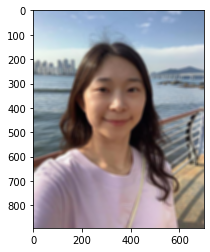

In [256]:
# (13,13)은 blurring kernel size를 뜻합니다
# 다양하게 바꿔보세요
img_orig_blur = cv2.blur(img_orig1, (13,13))

# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)   
plt.imshow(cv2.cvtColor(img_orig_blur, cv2.COLOR_BGR2RGB))
plt.show()

흐려진 이미지에서 세그멘테이션 마스크를 이용해서 배경만 추출해보자.

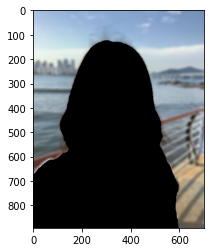

In [257]:
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경) 
img_mask_color = cv2.cvtColor(img_mask, cv2.COLOR_GRAY2BGR)

# cv2.bitwise_not(): 이미지가 반전됩니다. 배경이 0 사람이 255 였으나
# 연산을 하고 나면 배경은 255 사람은 0입니다.
img_bg_mask = cv2.bitwise_not(img_mask_color)

# cv2.bitwise_and()을 사용하면 배경만 있는 영상을 얻을 수 있습니다.
# 0과 어떤 수를 bitwise_and 연산을 해도 0이 되기 때문에 
# 사람이 0인 경우에는 사람이 있던 모든 픽셀이 0이 됩니다. 결국 사람이 사라지고 배경만 남아요!
img_bg_blur = cv2.bitwise_and(img_orig_blur, img_bg_mask)
plt.imshow(cv2.cvtColor(img_bg_blur, cv2.COLOR_BGR2RGB))
plt.show()

bitwise_not 함수를 이용하면 이미지가 반전된다. 원래 마스크에서는 배경이 0, 사람이 255였으니 bitwise_not 연산을 하고 나면 배경은 255, 사람은 0이 된다.

반전된 세그멘테이션 결과를 이용해서 이미지와 bitwise_and 연산을 수행하면 배경만 있는 영상을 얻을 수 있다. 0과 어떤 수를 bitwise_and 연산을 해도 0이 되기 때문에 사람이 0인 경우에는 사람이 있던 모든 픽셀이 0이 된다. 결국 사람이 사라지게 되는 것이다.

## 셸로우 포커스 만들기 (5) 흐린 배경과 원본 영상 합성
---
이제 배경 영상과 사람 영상을 합치기만 하면 된다.

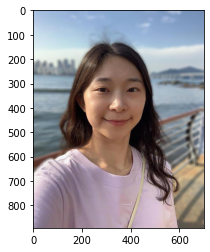

In [258]:
# np.where(조건, 참일때, 거짓일때)
# 세그멘테이션 마스크가 255인 부분만 원본 이미지 값을 가지고 오고 
# 아닌 영역은 블러된 이미지 값을 사용합니다.
img_concat1 = np.where(img_mask_color==255, img_orig1, img_bg_blur)
# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니 
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)
plt.imshow(cv2.cvtColor(img_concat1, cv2.COLOR_BGR2RGB))
plt.show()

세그멘테이션 마스크가 255인 부분만 원본 이미지 값을 가지고 오고 아닌 영역은 블러된 이미지 값을 사용한다. np.where(조건, 참일때, 거짓일때)의 형식의 코드를 사용했다.

https://numpy.org/doc/stable/reference/generated/numpy.where.html

인물모드가 완성되었다. 원본과 비교해 보자.
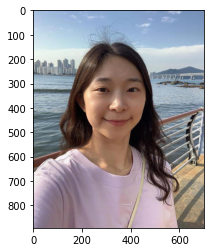 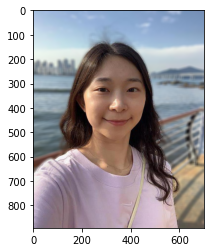

인물과 배경의 거리 차이가 있고 거리가 일정할수록 더 자연스러워 보인다.

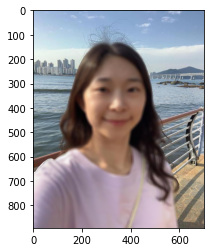

In [259]:
# Q. 이번에는 사람 부분을 블러로, 배경 부분을 원본으로 출력해볼까요?
# 힌트 : img_mask_color 옵션을 적절히 조정해주고, img_orig1, img_orig_blur 를 활용하세요.
img_concat1_1 = np.where(img_mask_color==0, img_orig1, img_orig_blur)
plt.imshow(cv2.cvtColor(img_concat1_1, cv2.COLOR_BGR2RGB))
plt.show()

사람이 블러처리가 되고, 배경이 그대로인 것을 확인할 수 있다.

### 나머지 사진들도 똑같이 진행해보자.
---

#### 두 번째 사진 진행

In [260]:
segvalues, output = model.segmentAsPascalvoc(img_path2) # segmentAsPascalvoc()함수를 호출 하여 입력된 이미지를 분할, 분할 출력의 배열을 가져옴, 분할은 pacalvoc 데이터로 학습된 모델을 이용                                                       

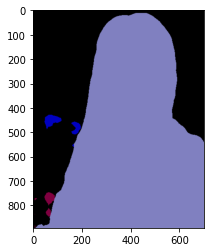

In [261]:
#segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 output을 matplotlib을 이용해 출력
plt.imshow(output)
plt.show()

In [262]:
segvalues # segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 배열값을 출력

{'class_ids': array([ 0,  9, 12, 15]),
 'masks': array([[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ...,  True,  True,  True],
        [False, False, False, ...,  True,  True,  True],
        [False, False, False, ...,  True,  True,  True]])}

In [263]:
#segvalues에 있는 class_ids를 담겨있는 값을 통해 pacalvoc에 담겨있는 라벨을 출력
for class_id in segvalues['class_ids']:
    print(LABEL_NAMES[class_id])

background
chair
dog
person


**dog가 있다고...? 사진 상으로는 강아지가 존재하지 않는데, 강아지를 감지하고 있다..**

In [264]:
# 아래 코드를 이해하지 않아도 좋습니다
# PixelLib에서 그대로 가져온 코드입니다
# 주목해야 할 것은 생상 코드 결과물이예요!

#컬러맵 만들기 
colormap = np.zeros((256, 3), dtype = int)
ind = np.arange(256, dtype=int)

for shift in reversed(range(8)):
    for channel in range(3):
        colormap[:, channel] |= ((ind >> channel) & 1) << shift
    ind >>= 3

colormap[:20] #생성한 20개의 컬러맵 출력

array([[  0,   0,   0],
       [128,   0,   0],
       [  0, 128,   0],
       [128, 128,   0],
       [  0,   0, 128],
       [128,   0, 128],
       [  0, 128, 128],
       [128, 128, 128],
       [ 64,   0,   0],
       [192,   0,   0],
       [ 64, 128,   0],
       [192, 128,   0],
       [ 64,   0, 128],
       [192,   0, 128],
       [ 64, 128, 128],
       [192, 128, 128],
       [  0,  64,   0],
       [128,  64,   0],
       [  0, 192,   0],
       [128, 192,   0]])

In [265]:
colormap[15] #컬러맵 15에 해당하는 배열 출력 (pacalvoc에 LABEL_NAMES 15번째인 사람)

array([192, 128, 128])

In [266]:
seg_color = (128,128,192) # 색상순서 변경 - colormap의 배열은 RGB 순이며 output의 배열은 BGR 순서로 채널 배치가 되어 있어서

In [267]:
# output 형태 확인
output.shape # output 배열은 모델이 분할한 결과로, 각 픽셀에 대한 색상 정보를 담고 있다.

(892, 700, 3)

(892, 700)


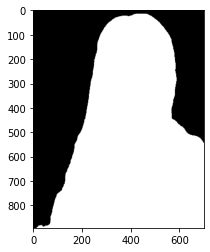

In [268]:
# output의 픽셀 별로 색상이 seg_color와 같다면 1(True), 다르다면 0(False)이 됩니다
# seg_color 값이 person을 값이 므로 사람이 있는 위치를 제외하고는 gray로 출력
# cmap 값을 변경하면 다른 색상으로 확인이 가능함
seg_map = np.all(output==seg_color, axis=-1) # output과 seg_color를 비교하여 모든 채널에 대해 같은 색상인지를 확인한다. 
                                             # axis=-1은 마지막 차원(컬러 채널)을 기준으로 비교하라는 의미한다.
print(seg_map.shape) 
plt.imshow(seg_map, cmap='gray') # cmap 파라미터를 설정하면 데이터의 값을 어떤 색상으로 나타낼지를 결정할 수 있다. 
                                 # 예를 들어, 'gray'로 설정하면 흑백 이미지처럼 보일 것이고, 'viridis', 'jet', 'hot' 등 다양한 컬러맵을 적용하여 데이터를 다양한 색상으로 표현한다.
                                 # seg_map의 True(1)는 흰색, False(0)는 검은색으로 표시된다.
plt.show()

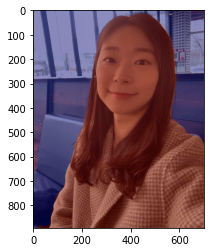

In [269]:
# 원본이미지를 img_show에 할당한뒤 이미지 사람이 있는 위치와 배경을 분리해서 표현한 color_mask 를 만든뒤 두 이미지를 합쳐서 출력
img_show = img_orig2.copy() # 원본 이미지를 수정하지 않고 복사본을 사용하기 img_show에 복자

# True과 False인 값을 각각 255과 0으로 바꿔줍니다
img_mask = seg_map.astype(np.uint8) * 255 # True는 사람 위치를 나타내며 255(흰색), False는 배경을 나타내며 0(검은색)
                                          # np.uint8 - 부호 없는 8비트 정수(unsigned 8-bit integer)
# 255와 0을 적당한 색상으로 바꿔봅니다 (색상 마스크 만들기)
color_mask = cv2.applyColorMap(img_mask, cv2.COLORMAP_JET) # img_mask에 적당한 컬러 맵을 적용하여 색상 마스크(color_mask)를 만든다.
                                                           # cv2.COLORMAP_JET을 사용하여 마스크 이미지의 값을 적절한 색상으로 매핑

# 원본 이미지와 마스크를 적당히 합쳐봅니다
# 0.6과 0.4는 두 이미지를 섞는 비율입니다.
img_show = cv2.addWeighted(img_show, 0.6, color_mask, 0.4, 0.0) # img_show와 color_mask를 일정 비율로 합성하여 최종적인 시각화 이미지를 만듦
                                                                # cv2.addWeighted() 함수를 사용하여 두 이미지를 섞어서 출력 이미지를 생성
                                                                # 첫 번째 이미지는 img_show로, 두 번째 이미지는 color_mask로 설정되었으며, 0.6과 0.4는 각 이미지의 가중치를 나타냄
plt.imshow(cv2.cvtColor(img_show, cv2.COLOR_BGR2RGB)) # img_show는 원본 이미지와 사람의 위치를 강조한 컬러 마스크를 합친 이미지
plt.show()

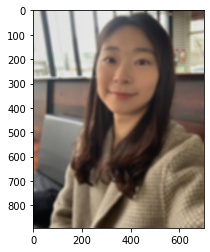

In [270]:
# (13,13)은 blurring kernel size를 뜻합니다
# 다양하게 바꿔보세요
img_orig_blur = cv2.blur(img_orig2, (13,13))

# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)   
plt.imshow(cv2.cvtColor(img_orig_blur, cv2.COLOR_BGR2RGB))
plt.show()

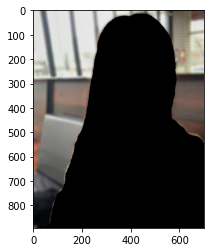

In [271]:
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경) 
img_mask_color = cv2.cvtColor(img_mask, cv2.COLOR_GRAY2BGR)

# cv2.bitwise_not(): 이미지가 반전됩니다. 배경이 0 사람이 255 였으나
# 연산을 하고 나면 배경은 255 사람은 0입니다.
img_bg_mask = cv2.bitwise_not(img_mask_color)

# cv2.bitwise_and()을 사용하면 배경만 있는 영상을 얻을 수 있습니다.
# 0과 어떤 수를 bitwise_and 연산을 해도 0이 되기 때문에 
# 사람이 0인 경우에는 사람이 있던 모든 픽셀이 0이 됩니다. 결국 사람이 사라지고 배경만 남아요!
img_bg_blur = cv2.bitwise_and(img_orig_blur, img_bg_mask)
plt.imshow(cv2.cvtColor(img_bg_blur, cv2.COLOR_BGR2RGB))
plt.show()

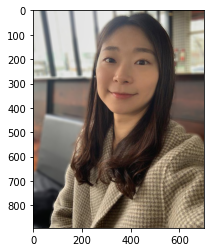

In [272]:
# np.where(조건, 참일때, 거짓일때)
# 세그멘테이션 마스크가 255인 부분만 원본 이미지 값을 가지고 오고 
# 아닌 영역은 블러된 이미지 값을 사용합니다.
img_concat2 = np.where(img_mask_color==255, img_orig2, img_bg_blur)
# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니 
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)
plt.imshow(cv2.cvtColor(img_concat2, cv2.COLOR_BGR2RGB))
plt.show()

### 원본과 비교
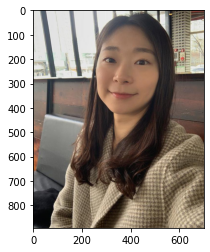 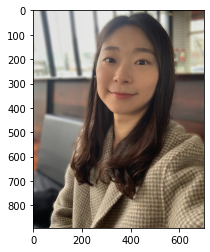

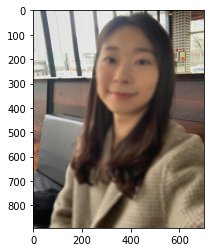

In [273]:
# Q. 이번에는 사람 부분을 블러로, 배경 부분을 원본으로 출력해볼까요?
# 힌트 : img_mask_color 옵션을 적절히 조정해주고, img_orig, img_orig_blur 를 활용하세요.
img_concat2_2 = np.where(img_mask_color==0, img_orig2, img_orig_blur)
plt.imshow(cv2.cvtColor(img_concat2_2, cv2.COLOR_BGR2RGB))
plt.show()

#### 세 번째 사진 진행


In [274]:
segvalues, output = model.segmentAsPascalvoc(img_path3) # segmentAsPascalvoc()함수를 호출 하여 입력된 이미지를 분할, 분할 출력의 배열을 가져옴, 분할은 pacalvoc 데이터로 학습된 모델을 이용                                                       

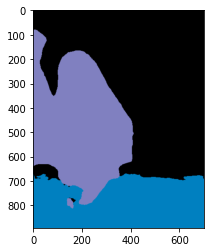

In [275]:
#segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 output을 matplotlib을 이용해 출력
plt.imshow(output)
plt.show()

In [276]:
segvalues # segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 배열값을 출력

{'class_ids': array([ 0, 11, 15]),
 'masks': array([[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True]])}

In [277]:
#segvalues에 있는 class_ids를 담겨있는 값을 통해 pacalvoc에 담겨있는 라벨을 출력
for class_id in segvalues['class_ids']:
    print(LABEL_NAMES[class_id])

background
diningtable
person


In [278]:
# 아래 코드를 이해하지 않아도 좋습니다
# PixelLib에서 그대로 가져온 코드입니다
# 주목해야 할 것은 생상 코드 결과물이예요!

#컬러맵 만들기 
colormap = np.zeros((256, 3), dtype = int)
ind = np.arange(256, dtype=int)

for shift in reversed(range(8)):
    for channel in range(3):
        colormap[:, channel] |= ((ind >> channel) & 1) << shift
    ind >>= 3

colormap[:20] #생성한 20개의 컬러맵 출력

array([[  0,   0,   0],
       [128,   0,   0],
       [  0, 128,   0],
       [128, 128,   0],
       [  0,   0, 128],
       [128,   0, 128],
       [  0, 128, 128],
       [128, 128, 128],
       [ 64,   0,   0],
       [192,   0,   0],
       [ 64, 128,   0],
       [192, 128,   0],
       [ 64,   0, 128],
       [192,   0, 128],
       [ 64, 128, 128],
       [192, 128, 128],
       [  0,  64,   0],
       [128,  64,   0],
       [  0, 192,   0],
       [128, 192,   0]])

In [279]:
colormap[15] #컬러맵 15에 해당하는 배열 출력 (pacalvoc에 LABEL_NAMES 15번째인 사람)

array([192, 128, 128])

In [280]:
seg_color = (128,128,192) # 색상순서 변경 - colormap의 배열은 RGB 순이며 output의 배열은 BGR 순서로 채널 배치가 되어 있어서

In [281]:
# output 형태 확인
output.shape # output 배열은 모델이 분할한 결과로, 각 픽셀에 대한 색상 정보를 담고 있다.

(892, 700, 3)

(892, 700)


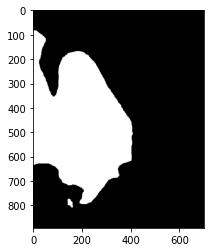

In [282]:
# output의 픽셀 별로 색상이 seg_color와 같다면 1(True), 다르다면 0(False)이 됩니다
# seg_color 값이 person을 값이 므로 사람이 있는 위치를 제외하고는 gray로 출력
# cmap 값을 변경하면 다른 색상으로 확인이 가능함
seg_map = np.all(output==seg_color, axis=-1) # output과 seg_color를 비교하여 모든 채널에 대해 같은 색상인지를 확인한다. 
                                             # axis=-1은 마지막 차원(컬러 채널)을 기준으로 비교하라는 의미한다.
print(seg_map.shape) 
plt.imshow(seg_map, cmap='gray') # cmap 파라미터를 설정하면 데이터의 값을 어떤 색상으로 나타낼지를 결정할 수 있다. 
                                 # 예를 들어, 'gray'로 설정하면 흑백 이미지처럼 보일 것이고, 'viridis', 'jet', 'hot' 등 다양한 컬러맵을 적용하여 데이터를 다양한 색상으로 표현한다.
                                 # seg_map의 True(1)는 흰색, False(0)는 검은색으로 표시된다.
plt.show()

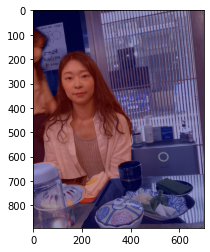

In [283]:
# 원본이미지를 img_show에 할당한뒤 이미지 사람이 있는 위치와 배경을 분리해서 표현한 color_mask 를 만든뒤 두 이미지를 합쳐서 출력
img_show = img_orig3.copy() # 원본 이미지를 수정하지 않고 복사본을 사용하기 img_show에 복자

# True과 False인 값을 각각 255과 0으로 바꿔줍니다
img_mask = seg_map.astype(np.uint8) * 255 # True는 사람 위치를 나타내며 255(흰색), False는 배경을 나타내며 0(검은색)
                                          # np.uint8 - 부호 없는 8비트 정수(unsigned 8-bit integer)
# 255와 0을 적당한 색상으로 바꿔봅니다 (색상 마스크 만들기)
color_mask = cv2.applyColorMap(img_mask, cv2.COLORMAP_JET) # img_mask에 적당한 컬러 맵을 적용하여 색상 마스크(color_mask)를 만든다.
                                                           # cv2.COLORMAP_JET을 사용하여 마스크 이미지의 값을 적절한 색상으로 매핑

# 원본 이미지와 마스크를 적당히 합쳐봅니다
# 0.6과 0.4는 두 이미지를 섞는 비율입니다.
img_show = cv2.addWeighted(img_show, 0.6, color_mask, 0.4, 0.0) # img_show와 color_mask를 일정 비율로 합성하여 최종적인 시각화 이미지를 만듦
                                                                # cv2.addWeighted() 함수를 사용하여 두 이미지를 섞어서 출력 이미지를 생성
                                                                # 첫 번째 이미지는 img_show로, 두 번째 이미지는 color_mask로 설정되었으며, 0.6과 0.4는 각 이미지의 가중치를 나타냄
plt.imshow(cv2.cvtColor(img_show, cv2.COLOR_BGR2RGB)) # img_show는 원본 이미지와 사람의 위치를 강조한 컬러 마스크를 합친 이미지
plt.show()

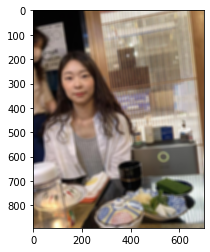

In [284]:
# (13,13)은 blurring kernel size를 뜻합니다
# 다양하게 바꿔보세요
img_orig_blur = cv2.blur(img_orig3, (13,13))

# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)   
plt.imshow(cv2.cvtColor(img_orig_blur, cv2.COLOR_BGR2RGB))
plt.show()

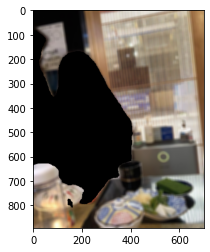

In [285]:
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경) 
img_mask_color = cv2.cvtColor(img_mask, cv2.COLOR_GRAY2BGR)

# cv2.bitwise_not(): 이미지가 반전됩니다. 배경이 0 사람이 255 였으나
# 연산을 하고 나면 배경은 255 사람은 0입니다.
img_bg_mask = cv2.bitwise_not(img_mask_color)

# cv2.bitwise_and()을 사용하면 배경만 있는 영상을 얻을 수 있습니다.
# 0과 어떤 수를 bitwise_and 연산을 해도 0이 되기 때문에 
# 사람이 0인 경우에는 사람이 있던 모든 픽셀이 0이 됩니다. 결국 사람이 사라지고 배경만 남아요!
img_bg_blur = cv2.bitwise_and(img_orig_blur, img_bg_mask)
plt.imshow(cv2.cvtColor(img_bg_blur, cv2.COLOR_BGR2RGB))
plt.show()

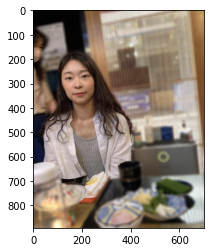

In [286]:
# np.where(조건, 참일때, 거짓일때)
# 세그멘테이션 마스크가 255인 부분만 원본 이미지 값을 가지고 오고 
# 아닌 영역은 블러된 이미지 값을 사용합니다.
img_concat3 = np.where(img_mask_color==255, img_orig3, img_bg_blur)
# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니 
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)
plt.imshow(cv2.cvtColor(img_concat3, cv2.COLOR_BGR2RGB))
plt.show()

### 원본과 비교

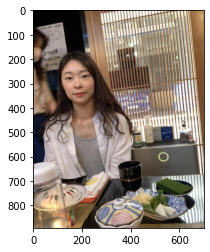 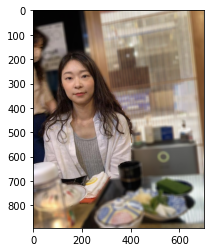

* 위에서 배경만 추출했을 때는, 뒤에 지나가는 행인도 제외가 되었었다. 하지만 블러 처리를 했을 때, 행인도 사람임에도 불구하고 블러처리가 된 것 같았는데, 원본에서도 지나가는 행인이 속도 때문인지 흐릿하게 보이는 것 같아, 행인도 블러 처리가 되지 않았을 것이라고 추측이 된다.

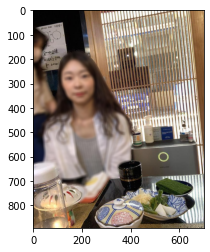

In [287]:
# Q. 이번에는 사람 부분을 블러로, 배경 부분을 원본으로 출력해볼까요?
# 힌트 : img_mask_color 옵션을 적절히 조정해주고, img_orig, img_orig_blur 를 활용하세요.
img_concat3_3 = np.where(img_mask_color==0, img_orig3, img_orig_blur)
plt.imshow(cv2.cvtColor(img_concat3_3, cv2.COLOR_BGR2RGB))
plt.show()

#### 네 번째 사진 진행

In [288]:
segvalues, output = model.segmentAsPascalvoc(img_path4) # segmentAsPascalvoc()함수를 호출 하여 입력된 이미지를 분할, 분할 출력의 배열을 가져옴, 분할은 pacalvoc 데이터로 학습된 모델을 이용                                                       

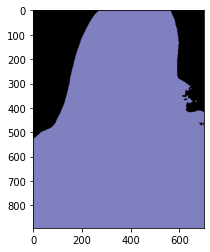

In [289]:
#segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 output을 matplotlib을 이용해 출력
plt.imshow(output)
plt.show()

In [290]:
segvalues # segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 배열값을 출력

{'class_ids': array([ 0, 15]),
 'masks': array([[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True]])}

In [291]:
#segvalues에 있는 class_ids를 담겨있는 값을 통해 pacalvoc에 담겨있는 라벨을 출력
for class_id in segvalues['class_ids']:
    print(LABEL_NAMES[class_id])

background
person


* 애매하고 작은 사물은 background로 감지하는 것 같다.

In [292]:
# 아래 코드를 이해하지 않아도 좋습니다
# PixelLib에서 그대로 가져온 코드입니다
# 주목해야 할 것은 생상 코드 결과물이예요!

#컬러맵 만들기 
colormap = np.zeros((256, 3), dtype = int)
ind = np.arange(256, dtype=int)

for shift in reversed(range(8)):
    for channel in range(3):
        colormap[:, channel] |= ((ind >> channel) & 1) << shift
    ind >>= 3

colormap[:20] #생성한 20개의 컬러맵 출력

array([[  0,   0,   0],
       [128,   0,   0],
       [  0, 128,   0],
       [128, 128,   0],
       [  0,   0, 128],
       [128,   0, 128],
       [  0, 128, 128],
       [128, 128, 128],
       [ 64,   0,   0],
       [192,   0,   0],
       [ 64, 128,   0],
       [192, 128,   0],
       [ 64,   0, 128],
       [192,   0, 128],
       [ 64, 128, 128],
       [192, 128, 128],
       [  0,  64,   0],
       [128,  64,   0],
       [  0, 192,   0],
       [128, 192,   0]])

In [293]:
colormap[15] #컬러맵 15에 해당하는 배열 출력 (pacalvoc에 LABEL_NAMES 15번째인 사람)

array([192, 128, 128])

In [294]:
seg_color = (128,128,192) # 색상순서 변경 - colormap의 배열은 RGB 순이며 output의 배열은 BGR 순서로 채널 배치가 되어 있어서

In [295]:
# output 형태 확인
output.shape # output 배열은 모델이 분할한 결과로, 각 픽셀에 대한 색상 정보를 담고 있다.

(892, 700, 3)

(892, 700)


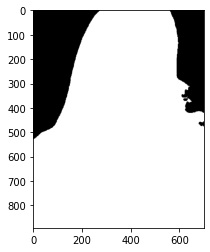

In [296]:
# output의 픽셀 별로 색상이 seg_color와 같다면 1(True), 다르다면 0(False)이 됩니다
# seg_color 값이 person을 값이 므로 사람이 있는 위치를 제외하고는 gray로 출력
# cmap 값을 변경하면 다른 색상으로 확인이 가능함
seg_map = np.all(output==seg_color, axis=-1) # output과 seg_color를 비교하여 모든 채널에 대해 같은 색상인지를 확인한다. 
                                             # axis=-1은 마지막 차원(컬러 채널)을 기준으로 비교하라는 의미한다.
print(seg_map.shape) 
plt.imshow(seg_map, cmap='gray') # cmap 파라미터를 설정하면 데이터의 값을 어떤 색상으로 나타낼지를 결정할 수 있다. 
                                 # 예를 들어, 'gray'로 설정하면 흑백 이미지처럼 보일 것이고, 'viridis', 'jet', 'hot' 등 다양한 컬러맵을 적용하여 데이터를 다양한 색상으로 표현한다.
                                 # seg_map의 True(1)는 흰색, False(0)는 검은색으로 표시된다.
plt.show()

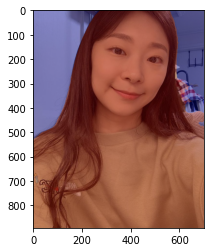

In [297]:
# 원본이미지를 img_show에 할당한뒤 이미지 사람이 있는 위치와 배경을 분리해서 표현한 color_mask 를 만든뒤 두 이미지를 합쳐서 출력
img_show = img_orig4.copy() # 원본 이미지를 수정하지 않고 복사본을 사용하기 img_show에 복자

# True과 False인 값을 각각 255과 0으로 바꿔줍니다
img_mask = seg_map.astype(np.uint8) * 255 # True는 사람 위치를 나타내며 255(흰색), False는 배경을 나타내며 0(검은색)
                                          # np.uint8 - 부호 없는 8비트 정수(unsigned 8-bit integer)
# 255와 0을 적당한 색상으로 바꿔봅니다 (색상 마스크 만들기)
color_mask = cv2.applyColorMap(img_mask, cv2.COLORMAP_JET) # img_mask에 적당한 컬러 맵을 적용하여 색상 마스크(color_mask)를 만든다.
                                                           # cv2.COLORMAP_JET을 사용하여 마스크 이미지의 값을 적절한 색상으로 매핑

# 원본 이미지와 마스크를 적당히 합쳐봅니다
# 0.6과 0.4는 두 이미지를 섞는 비율입니다.
img_show = cv2.addWeighted(img_show, 0.6, color_mask, 0.4, 0.0) # img_show와 color_mask를 일정 비율로 합성하여 최종적인 시각화 이미지를 만듦
                                                                # cv2.addWeighted() 함수를 사용하여 두 이미지를 섞어서 출력 이미지를 생성
                                                                # 첫 번째 이미지는 img_show로, 두 번째 이미지는 color_mask로 설정되었으며, 0.6과 0.4는 각 이미지의 가중치를 나타냄
plt.imshow(cv2.cvtColor(img_show, cv2.COLOR_BGR2RGB)) # img_show는 원본 이미지와 사람의 위치를 강조한 컬러 마스크를 합친 이미지
plt.show()

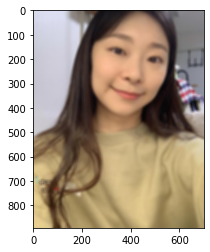

In [298]:
# (13,13)은 blurring kernel size를 뜻합니다
# 다양하게 바꿔보세요
img_orig_blur = cv2.blur(img_orig4, (13,13))

# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)   
plt.imshow(cv2.cvtColor(img_orig_blur, cv2.COLOR_BGR2RGB))
plt.show()

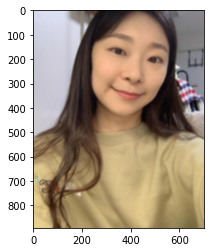

In [299]:
# 커널 사이즈를 바꿔보자
# (8,8)은 blurring kernel size를 뜻합니다
# 다양하게 바꿔보세요
img_orig_blur1 = cv2.blur(img_orig4, (8,8))

# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)   
plt.imshow(cv2.cvtColor(img_orig_blur1, cv2.COLOR_BGR2RGB))
plt.show()

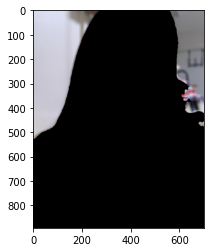

In [300]:
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경) 
img_mask_color = cv2.cvtColor(img_mask, cv2.COLOR_GRAY2BGR)

# cv2.bitwise_not(): 이미지가 반전됩니다. 배경이 0 사람이 255 였으나
# 연산을 하고 나면 배경은 255 사람은 0입니다.
img_bg_mask = cv2.bitwise_not(img_mask_color)

# cv2.bitwise_and()을 사용하면 배경만 있는 영상을 얻을 수 있습니다.
# 0과 어떤 수를 bitwise_and 연산을 해도 0이 되기 때문에 
# 사람이 0인 경우에는 사람이 있던 모든 픽셀이 0이 됩니다. 결국 사람이 사라지고 배경만 남아요!
img_bg_blur = cv2.bitwise_and(img_orig_blur, img_bg_mask)
plt.imshow(cv2.cvtColor(img_bg_blur, cv2.COLOR_BGR2RGB))
plt.show()

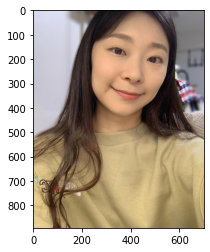

In [301]:
# np.where(조건, 참일때, 거짓일때)
# 세그멘테이션 마스크가 255인 부분만 원본 이미지 값을 가지고 오고 
# 아닌 영역은 블러된 이미지 값을 사용합니다.
img_concat4 = np.where(img_mask_color==255, img_orig4, img_bg_blur)
# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니 
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)
plt.imshow(cv2.cvtColor(img_concat4, cv2.COLOR_BGR2RGB))
plt.show()

### 원본과 비교

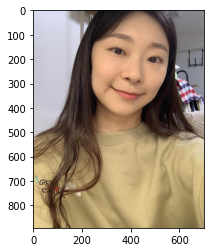 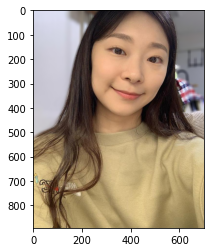

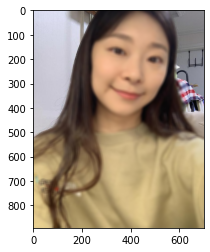

In [302]:
# Q. 이번에는 사람 부분을 블러로, 배경 부분을 원본으로 출력해볼까요?
# 힌트 : img_mask_color 옵션을 적절히 조정해주고, img_orig, img_orig_blur 를 활용하세요.
img_concat4_4 = np.where(img_mask_color==0, img_orig4, img_orig_blur)
plt.imshow(cv2.cvtColor(img_concat4_4, cv2.COLOR_BGR2RGB))
plt.show()

#### 우리 강아지 가비는 어떻게 블러 처리가 진행되는지 보자
---

In [303]:
# # 이미지 회전시키기
# def rotate_image(input_image_path, output_image_path, angle):
#     img = Image.open(input_image_path)
#     rotated_img = img.rotate(angle, expand=True)  # expand=True로 설정하면 이미지를 회전한 후에도 전체 이미지를 포함할 수 있게 해줘
#     rotated_img.save(output_image_path)

# # 사용 예시
# # input_image_path = '원하는_이미지_파일명.jpg'
# # output_image_path = '회전된_이미지_파일명.jpg'
# rotation_angle = -180 # 회전할 각도를 지정 (양수 또는 음수 모두 가능)

# rotate_image(img_path_gabi, img_path_gabi, rotation_angle)

In [304]:
# img_orig_gabi = cv2.imread(img_path_gabi) 

# plt.imshow(cv2.cvtColor(img_orig_gabi, cv2.COLOR_BGR2RGB)) # 이미지 색상 채널을 변경 (BGR 형식을 RGB 형식으로 변경)
# plt.show() # 저장된 데이터를 이미지의 형식으로 표시

In [305]:
segvalues, output = model.segmentAsPascalvoc(img_path_gabi) # segmentAsPascalvoc()함수를 호출 하여 입력된 이미지를 분할, 분할 출력의 배열을 가져옴, 분할은 pacalvoc 데이터로 학습된 모델을 이용                                                       

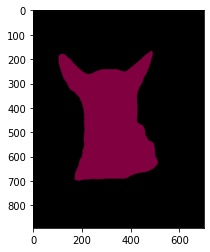

In [306]:
#segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 output을 matplotlib을 이용해 출력
plt.imshow(output)
plt.show()

In [307]:
segvalues # segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 배열값을 출력

{'class_ids': array([ 0, 12]),
 'masks': array([[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]])}

In [308]:
#segvalues에 있는 class_ids를 담겨있는 값을 통해 pacalvoc에 담겨있는 라벨을 출력
for class_id in segvalues['class_ids']:
    print(LABEL_NAMES[class_id])

background
dog


* 강아지를 잘 인식하고 있는 것 같다.
* 하지만 사람도 인식을 했는데, 사진 상에는 사람이 존재하지 않는다.

In [309]:
# 아래 코드를 이해하지 않아도 좋습니다
# PixelLib에서 그대로 가져온 코드입니다
# 주목해야 할 것은 생상 코드 결과물이예요!

#컬러맵 만들기 
colormap = np.zeros((256, 3), dtype = int)
ind = np.arange(256, dtype=int)

for shift in reversed(range(8)):
    for channel in range(3):
        colormap[:, channel] |= ((ind >> channel) & 1) << shift
    ind >>= 3

colormap[:20] #생성한 20개의 컬러맵 출력

array([[  0,   0,   0],
       [128,   0,   0],
       [  0, 128,   0],
       [128, 128,   0],
       [  0,   0, 128],
       [128,   0, 128],
       [  0, 128, 128],
       [128, 128, 128],
       [ 64,   0,   0],
       [192,   0,   0],
       [ 64, 128,   0],
       [192, 128,   0],
       [ 64,   0, 128],
       [192,   0, 128],
       [ 64, 128, 128],
       [192, 128, 128],
       [  0,  64,   0],
       [128,  64,   0],
       [  0, 192,   0],
       [128, 192,   0]])

In [310]:
# 강아지를 나타내는 12번째 색상은?
colormap[12] #컬러맵 15에 해당하는 배열 출력 (pacalvoc에 LABEL_NAMES 12번째인 강아지)

array([ 64,   0, 128])

In [311]:
seg_color = (128, 0, 64) # 색상순서 변경 - colormap의 배열은 RGB 순이며 output의 배열은 BGR 순서로 채널 배치가 되어 있어서

In [312]:
# output 형태 확인
output.shape # output 배열은 모델이 분할한 결과로, 각 픽셀에 대한 색상 정보를 담고 있다.

(892, 700, 3)

(892, 700)


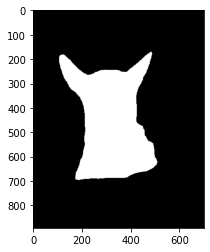

In [313]:
# output의 픽셀 별로 색상이 seg_color와 같다면 1(True), 다르다면 0(False)이 됩니다
# seg_color 값이 person을 값이 므로 사람이 있는 위치를 제외하고는 gray로 출력
# cmap 값을 변경하면 다른 색상으로 확인이 가능함
seg_map = np.all(output==seg_color, axis=-1) # output과 seg_color를 비교하여 모든 채널에 대해 같은 색상인지를 확인한다. 
                                             # axis=-1은 마지막 차원(컬러 채널)을 기준으로 비교하라는 의미한다.
print(seg_map.shape) 
plt.imshow(seg_map, cmap='gray') # cmap 파라미터를 설정하면 데이터의 값을 어떤 색상으로 나타낼지를 결정할 수 있다. 
                                 # 예를 들어, 'gray'로 설정하면 흑백 이미지처럼 보일 것이고, 'viridis', 'jet', 'hot' 등 다양한 컬러맵을 적용하여 데이터를 다양한 색상으로 표현한다.
                                 # seg_map의 True(1)는 흰색, False(0)는 검은색으로 표시된다.
plt.show()

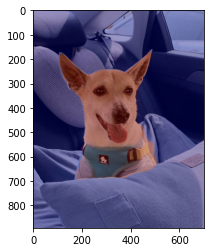

In [314]:
# 원본이미지를 img_show에 할당한뒤 이미지 사람이 있는 위치와 배경을 분리해서 표현한 color_mask 를 만든뒤 두 이미지를 합쳐서 출력
img_show = img_orig_gabi.copy() # 원본 이미지를 수정하지 않고 복사본을 사용하기 img_show에 복자

# True과 False인 값을 각각 255과 0으로 바꿔줍니다
img_mask = seg_map.astype(np.uint8) * 255 # True는 사람 위치를 나타내며 255(흰색), False는 배경을 나타내며 0(검은색)
                                          # np.uint8 - 부호 없는 8비트 정수(unsigned 8-bit integer)
# 255와 0을 적당한 색상으로 바꿔봅니다 (색상 마스크 만들기)
color_mask = cv2.applyColorMap(img_mask, cv2.COLORMAP_JET) # img_mask에 적당한 컬러 맵을 적용하여 색상 마스크(color_mask)를 만든다.
                                                           # cv2.COLORMAP_JET을 사용하여 마스크 이미지의 값을 적절한 색상으로 매핑

# 원본 이미지와 마스크를 적당히 합쳐봅니다
# 0.6과 0.4는 두 이미지를 섞는 비율입니다.
img_show = cv2.addWeighted(img_show, 0.6, color_mask, 0.4, 0.0) # img_show와 color_mask를 일정 비율로 합성하여 최종적인 시각화 이미지를 만듦
                                                                # cv2.addWeighted() 함수를 사용하여 두 이미지를 섞어서 출력 이미지를 생성
                                                                # 첫 번째 이미지는 img_show로, 두 번째 이미지는 color_mask로 설정되었으며, 0.6과 0.4는 각 이미지의 가중치를 나타냄
plt.imshow(cv2.cvtColor(img_show, cv2.COLOR_BGR2RGB)) # img_show는 원본 이미지와 사람의 위치를 강조한 컬러 마스크를 합친 이미지
plt.show()

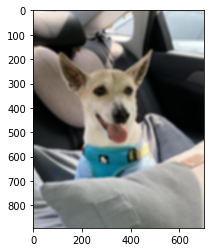

In [315]:
# (13,13)은 blurring kernel size를 뜻합니다
# 다양하게 바꿔보세요
img_orig_blur = cv2.blur(img_orig_gabi, (13,13))

# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)   
plt.imshow(cv2.cvtColor(img_orig_blur, cv2.COLOR_BGR2RGB))
plt.show()

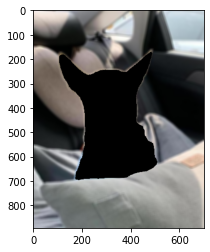

In [316]:
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경) 
img_mask_color = cv2.cvtColor(img_mask, cv2.COLOR_GRAY2BGR)

# cv2.bitwise_not(): 이미지가 반전됩니다. 배경이 0 사람이 255 였으나
# 연산을 하고 나면 배경은 255 사람은 0입니다.
img_bg_mask = cv2.bitwise_not(img_mask_color)

# cv2.bitwise_and()을 사용하면 배경만 있는 영상을 얻을 수 있습니다.
# 0과 어떤 수를 bitwise_and 연산을 해도 0이 되기 때문에 
# 사람이 0인 경우에는 사람이 있던 모든 픽셀이 0이 됩니다. 결국 사람이 사라지고 배경만 남아요!
img_bg_blur = cv2.bitwise_and(img_orig_blur, img_bg_mask)
plt.imshow(cv2.cvtColor(img_bg_blur, cv2.COLOR_BGR2RGB))
plt.show()

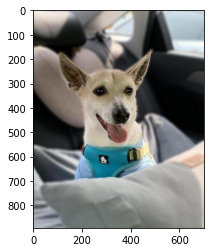

In [317]:
# np.where(조건, 참일때, 거짓일때)
# 세그멘테이션 마스크가 255인 부분만 원본 이미지 값을 가지고 오고 
# 아닌 영역은 블러된 이미지 값을 사용합니다.
img_concat5 = np.where(img_mask_color==255, img_orig_gabi, img_bg_blur)
# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니 
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)
plt.imshow(cv2.cvtColor(img_concat5, cv2.COLOR_BGR2RGB))
plt.show()

### 원본과 비교

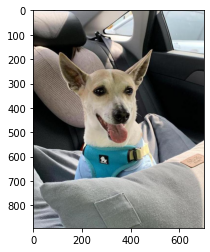 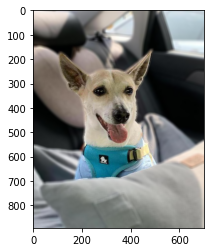

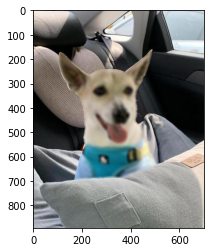

In [318]:
# Q. 이번에는 사람 부분을 블러로, 배경 부분을 원본으로 출력해볼까요?
# 힌트 : img_mask_color 옵션을 적절히 조정해주고, img_orig, img_orig_blur 를 활용하세요.
img_concat5_5 = np.where(img_mask_color==0, img_orig_gabi, img_orig_blur)
plt.imshow(cv2.cvtColor(img_concat5_5, cv2.COLOR_BGR2RGB))
plt.show()

## Step 2. 사진에서 문제점 찾기
---
인물 모드가 된 사진들에서 문제점을 찾아보자.

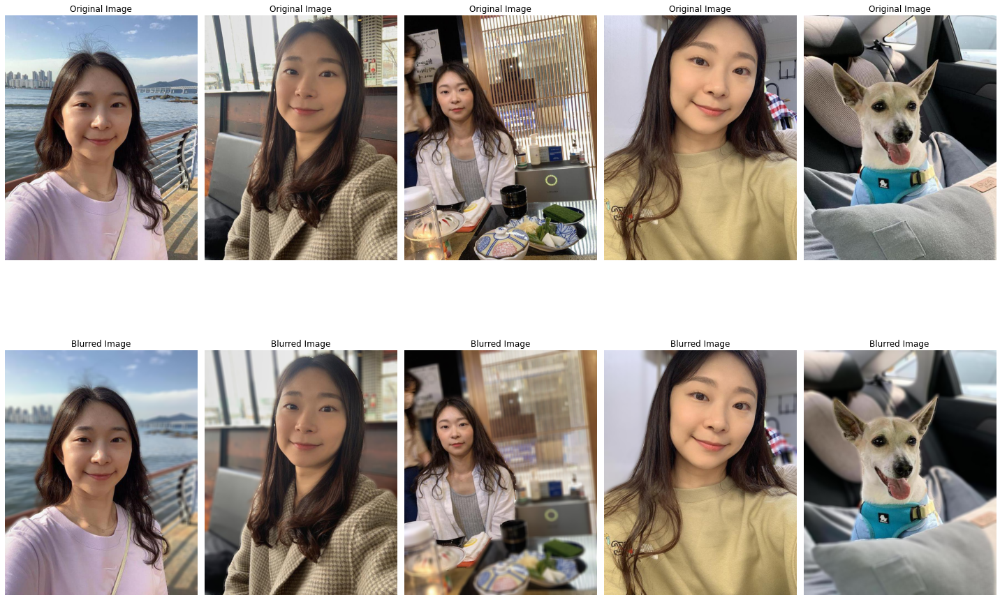

In [344]:
import matplotlib.pyplot as plt

image1 = cv2.cvtColor(img_orig1, cv2.COLOR_BGR2RGB)
image2 = cv2.cvtColor(img_orig2, cv2.COLOR_BGR2RGB)
image3 = cv2.cvtColor(img_orig3, cv2.COLOR_BGR2RGB)
image4 = cv2.cvtColor(img_orig4, cv2.COLOR_BGR2RGB)
image5 = cv2.cvtColor(img_orig_gabi, cv2.COLOR_BGR2RGB)

b_image1 = cv2.cvtColor(img_concat1, cv2.COLOR_BGR2RGB)
b_image2 = cv2.cvtColor(img_concat2, cv2.COLOR_BGR2RGB)
b_image3 = cv2.cvtColor(img_concat3, cv2.COLOR_BGR2RGB)
b_image4 = cv2.cvtColor(img_concat4, cv2.COLOR_BGR2RGB)
b_image5 = cv2.cvtColor(img_concat5, cv2.COLOR_BGR2RGB)

images = [image1, image2, image3, image4, image5]
blurred_images = [b_image1, b_image2, b_image3, b_image4, b_image5]

plt.figure(figsize=(20, 15))

for idx, image in enumerate(images):
    plt.subplot(2, 5, idx+1)
    plt.imshow(image, cmap=None)
    plt.title('Original Image')
    plt.axis('off')
    
for idx, image in enumerate(blurred_images):
    plt.subplot(2, 5, len(images)+idx+1)
    plt.imshow(image)
    plt.title('Blurred Image')
    plt.axis('off')
    
# 간격 조절
# plt.subplots_adjust(wspace=0.2, hspace=0)  # 가로 간격과 세로 간격 조절
plt.tight_layout() # subplot 간의 간격을 조절하여 subplot들이 균일하게 배치

plt.show()

### 몇 가지 문제점이 보인다.
---
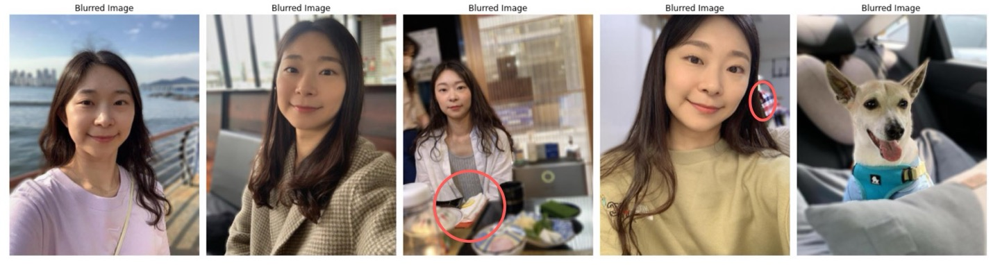


* 동그라미를 친 곳은 사람이 아니고, 사물인데도 블러 처리가 잘 안 된 것을 확인할 수 있다.
* 아마도 사람과 가까운 사물들 중에서 복잡한 형태를 띄고 있거나, 어떤 사물인지 명확한 추측이 안 되는 사물은 블러 처리가 잘 안 되는 것 같다.
* 사물이 복잡하게 구성되어 있을수록 블러 처리가 잘 안 되는 느낌이다.
* 그 외에는 블러 처리가 꽤 잘 된 것을 확인할 수 있다.

## Step 3. 해결 방법을 제안해 보기
---
#### 1. 블러 대신 양방향 필터를 적용해 보자

마스킹 필터에서 블러(Blur) 대신 양방향 필터(Bilateral Filter)를 사용하는 것은 이미지 처리에서 엣지 보존 및 선명도 강조 측면에서 더 좋은 결과를 제공할 수 있습니다.

블러(Blur) vs. 양방향 필터(Bilateral Filter):

블러(Blur): 이미지의 픽셀 값을 평균화하여 부드럽게 만드는 필터링 기법입니다. 이는 이미지를 흐릿하게 만들어 경계를 모호하게 할 수 있습니다. 경계가 흐릿해지면 마스킹된 영역의 경계도 흐려지게 되어 선명도와 디테일이 손실될 수 있습니다.

양방향 필터(Bilateral Filter): 이미지의 블러링을 수행하면서도 엣지 정보를 보존하는 필터입니다. 이 필터는 픽셀을 블러 처리하는 동시에 주변 픽셀과의 값 차이를 고려하여 엣지를 보존합니다. 따라서 더 선명한 엣지를 유지하면서 노이즈를 줄일 수 있습니다.
Masking에 양방향 필터 적용:

양방향 필터를 사용하면 마스킹하려는 이미지를 블러 처리할 때에도 엣지를 보존하여 경계를 더욱 명확하게 유지할 수 있습니다. 마스킹된 영역과 주변 배경 사이의 경계를 더 정확하게 유지하면서, 더 나은 시각적 구분을 제공합니다
.
결과적으로, 마스킹 필터에 양방향 필터를 적용하면 블러링을 수행하면서도 엣지를 보존하여 이미지의 선명도를 유지하면서 명확한 마스킹을 얻을 수 있습니다.

양방향 필터를 사용함으로써 마스킹된 영역과 배경 간의 경계를 더욱 선명하게 유지하면서도 필터링 작업을 수행할 수 있어, 마스킹 작업에 더 좋은 결과를 얻을 수 있을 것입니다.

-ChatGPT-

#### 구현이 가능할 것 같으므로 한 번 Bilateral Filter로 진행해보자.

가장 블러 처리가 잘 안 된 **세 번째 사진**을 가지고 진행해보겠다.

In [348]:
segvalues, output = model.segmentAsPascalvoc(img_path3) # segmentAsPascalvoc()함수를 호출 하여 입력된 이미지를 분할, 분할 출력의 배열을 가져옴, 분할은 pacalvoc 데이터로 학습된 모델을 이용                                                

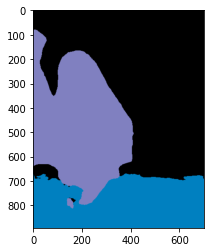

In [349]:
#segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 output을 matplotlib을 이용해 출력
plt.imshow(output)
plt.show()

In [350]:
segvalues # segmentAsPascalvoc() 함수를 호출하여 입력된 이미지를 분할한 뒤 나온 결과값 중 배열값을 출력

{'class_ids': array([ 0, 11, 15]),
 'masks': array([[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True]])}

In [351]:
#segvalues에 있는 class_ids를 담겨있는 값을 통해 pacalvoc에 담겨있는 라벨을 출력
for class_id in segvalues['class_ids']:
    print(LABEL_NAMES[class_id])

background
diningtable
person


In [352]:
# 아래 코드를 이해하지 않아도 좋습니다
# PixelLib에서 그대로 가져온 코드입니다
# 주목해야 할 것은 생상 코드 결과물이예요!

#컬러맵 만들기 
colormap = np.zeros((256, 3), dtype = int)
ind = np.arange(256, dtype=int)

for shift in reversed(range(8)):
    for channel in range(3):
        colormap[:, channel] |= ((ind >> channel) & 1) << shift
    ind >>= 3

colormap[:20] #생성한 20개의 컬러맵 출력

array([[  0,   0,   0],
       [128,   0,   0],
       [  0, 128,   0],
       [128, 128,   0],
       [  0,   0, 128],
       [128,   0, 128],
       [  0, 128, 128],
       [128, 128, 128],
       [ 64,   0,   0],
       [192,   0,   0],
       [ 64, 128,   0],
       [192, 128,   0],
       [ 64,   0, 128],
       [192,   0, 128],
       [ 64, 128, 128],
       [192, 128, 128],
       [  0,  64,   0],
       [128,  64,   0],
       [  0, 192,   0],
       [128, 192,   0]])

In [353]:
colormap[15] #컬러맵 15에 해당하는 배열 출력 (pacalvoc에 LABEL_NAMES 15번째인 사람)

array([192, 128, 128])

In [354]:
seg_color = (128,128,192) # 색상순서 변경 - colormap의 배열은 RGB 순이며 output의 배열은 BGR 순서로 채널 배치가 되어 있어서

In [355]:
# output 형태 확인
output.shape # output 배열은 모델이 분할한 결과로, 각 픽셀에 대한 색상 정보를 담고 있다.

(892, 700, 3)

(892, 700)


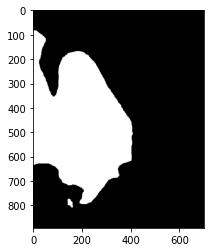

In [356]:
# output의 픽셀 별로 색상이 seg_color와 같다면 1(True), 다르다면 0(False)이 됩니다
# seg_color 값이 person을 값이 므로 사람이 있는 위치를 제외하고는 gray로 출력
# cmap 값을 변경하면 다른 색상으로 확인이 가능함
seg_map = np.all(output==seg_color, axis=-1) # output과 seg_color를 비교하여 모든 채널에 대해 같은 색상인지를 확인한다. 
                                             # axis=-1은 마지막 차원(컬러 채널)을 기준으로 비교하라는 의미한다.
print(seg_map.shape) 
plt.imshow(seg_map, cmap='gray') # cmap 파라미터를 설정하면 데이터의 값을 어떤 색상으로 나타낼지를 결정할 수 있다. 
                                 # 예를 들어, 'gray'로 설정하면 흑백 이미지처럼 보일 것이고, 'viridis', 'jet', 'hot' 등 다양한 컬러맵을 적용하여 데이터를 다양한 색상으로 표현한다.
                                 # seg_map의 True(1)는 흰색, False(0)는 검은색으로 표시된다.
plt.show()

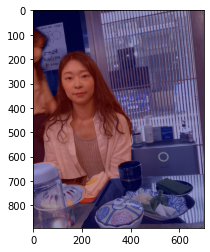

In [357]:
# 원본이미지를 img_show에 할당한뒤 이미지 사람이 있는 위치와 배경을 분리해서 표현한 color_mask 를 만든뒤 두 이미지를 합쳐서 출력
img_show = img_orig3.copy() # 원본 이미지를 수정하지 않고 복사본을 사용하기 img_show에 복자

# True과 False인 값을 각각 255과 0으로 바꿔줍니다
img_mask = seg_map.astype(np.uint8) * 255 # True는 사람 위치를 나타내며 255(흰색), False는 배경을 나타내며 0(검은색)
                                          # np.uint8 - 부호 없는 8비트 정수(unsigned 8-bit integer)
# 255와 0을 적당한 색상으로 바꿔봅니다 (색상 마스크 만들기)
color_mask = cv2.applyColorMap(img_mask, cv2.COLORMAP_JET) # img_mask에 적당한 컬러 맵을 적용하여 색상 마스크(color_mask)를 만든다.
                                                           # cv2.COLORMAP_JET을 사용하여 마스크 이미지의 값을 적절한 색상으로 매핑

# 원본 이미지와 마스크를 적당히 합쳐봅니다
# 0.6과 0.4는 두 이미지를 섞는 비율입니다.
img_show = cv2.addWeighted(img_show, 0.6, color_mask, 0.4, 0.0) # img_show와 color_mask를 일정 비율로 합성하여 최종적인 시각화 이미지를 만듦
                                                                # cv2.addWeighted() 함수를 사용하여 두 이미지를 섞어서 출력 이미지를 생성
                                                                # 첫 번째 이미지는 img_show로, 두 번째 이미지는 color_mask로 설정되었으며, 0.6과 0.4는 각 이미지의 가중치를 나타냄
plt.imshow(cv2.cvtColor(img_show, cv2.COLOR_BGR2RGB)) # img_show는 원본 이미지와 사람의 위치를 강조한 컬러 마스크를 합친 이미지
plt.show()

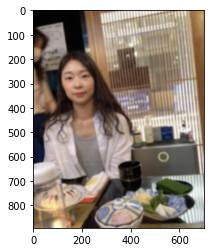

In [384]:
# 양방향 필터(Bilateral Filter)를 사용하여 이미지 처리
# (5, 75, 75)는 필터의 크기와 시그마 값에 대한 매개변수입니다. 이 값을 변경하여 다양한 효과를 확인할 수 있습니다.
img_orig_bilateral = cv2.bilateralFilter(img_orig3, 10, 600, 600)

# 이미지 출력
plt.imshow(cv2.cvtColor(img_orig_bilateral, cv2.COLOR_BGR2RGB))
plt.show()

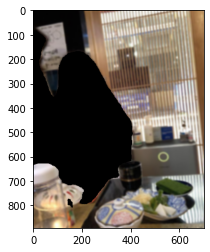

In [385]:
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경) 
img_mask_color = cv2.cvtColor(img_mask, cv2.COLOR_GRAY2BGR)

# cv2.bitwise_not(): 이미지가 반전됩니다. 배경이 0 사람이 255 였으나
# 연산을 하고 나면 배경은 255 사람은 0입니다.
img_bg_mask = cv2.bitwise_not(img_mask_color)

# cv2.bitwise_and()을 사용하면 배경만 있는 영상을 얻을 수 있습니다.
# 0과 어떤 수를 bitwise_and 연산을 해도 0이 되기 때문에 
# 사람이 0인 경우에는 사람이 있던 모든 픽셀이 0이 됩니다. 결국 사람이 사라지고 배경만 남아요!
img_bg_bilateral = cv2.bitwise_and(img_orig_bilateral, img_bg_mask)
plt.imshow(cv2.cvtColor(img_bg_bilateral, cv2.COLOR_BGR2RGB))
plt.show()

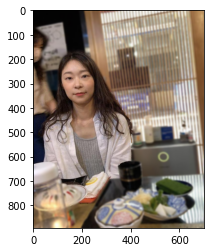

In [386]:
# np.where(조건, 참일때, 거짓일때)
# 세그멘테이션 마스크가 255인 부분만 원본 이미지 값을 가지고 오고 
# 아닌 영역은 블러된 이미지 값을 사용합니다.
img_concat3 = np.where(img_mask_color==255, img_orig3, img_bg_bilateral)
# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니 
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)
plt.imshow(cv2.cvtColor(img_concat3, cv2.COLOR_BGR2RGB))
plt.show()

### Blur vs Bilateral Filter
---

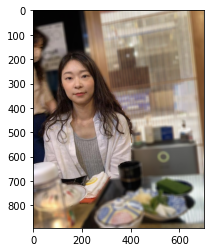 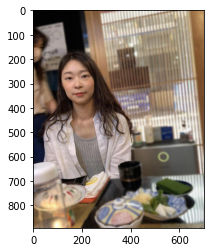

* 좀 더 흐릿하게 만들기 위해 시그마 값에 대한 매개변수를 조절했는데도, 뭔가 blur 처리한 것보다 더 나은 성능을 보여주는지는 모르겠다.
* 무조건적으로 Bilateral Filter가 Blur보다 좀 더 인물 사진을 만들어 준다고 볼 수는 없을 것 같다.

#### 2. 다른 Pre-trained 모델 선택하기 

* PSPNet: PSPNet은 피라미드 적용된 컨볼루션 네트워크로, 다양한 크기의 receptive field를 이용하여 이미지 컨텍스트를 잘 파악한다.
* HRNet: HRNet은 High-Resolution Networks로, 다양한 해상도의 정보를 유지하면서 세그멘테이션을 수행하여 성능을 향상시키는 데 효과적이다.
* UNet: UNet은 이미지 분할 작업에서 인기 있는 구조 중 하나로, 생물 의학 분야 등에서도 많이 사용된다. UNet 및 그 파생 버전들은 정확성과 성능면에서 강력한 결과를 보여준다.

어떤 사전 훈련된 모델이 최적인지는 데이터의 특성, 사용 환경, 성능 요구 사항 등에 따라 다를 수 있다. 따라서 모델을 선택할 때는 해당 작업에 대한 실험 및 검증을 통해 최적의 모델을 선정하는 것이 중요하다. 종종 사전 훈련된 모델을 기반으로 파인튜닝하여 특정 작업에 더 적합하게 만드는 것이 유용할 수 있다.

## 회고문

segmentaion을 이용해서 이렇게 아이폰 인물모드를 구현해볼 수 있어서 신기했다. 결과를 이미지로 출력하는 것은 원본 이미지의 변화를 확인할 수 있어서 흥미롭고 재미있는 것 같다. 

다만 처리를 하는 과정을 함수로 구현해서 다수의 사진에 적용을 하는 간단한 방법이 있을 것 같은데, 아직 코딩 초보자인 내가 class나 함수를 구현하지 못 해서 굉장히 번거로운 작업을 했던 것 같다. 언제 나는 코딩을 잘하게 될까? ㅠㅠ 

그 외에도 semantic segmentation mask의 오류를 보완할 수 있는 좋은 솔루션을 찾는 게 어려웠다. 아직 공부해야 할 게 참 많다고 느껴지는 이번 프로젝트였다.

모델이나 알고리즘에 대한 설명을 제시하는 사이트에 들어가도, 원리나 내용을 이해하는 게 아직도 어렵다. 어떻게 하면 잘 이해할 수 있을지 궁금하다. 공부는 끝이 없는 것 같다.


**KEEP:** 노드에서 제시되지 않은 코드로 결과물을 출력해야 할 때 구글링이나 gpt를 이용하여 시도하려고 한 점.

**PROBLEM:** 공부해야 하는 게 너무 많은 것 같다. 모델이나 알고리즘 설명 관련 사이트에서 내용을 이해하는 게 너무 어렵다. 제대로 이해하려고 하면 밑도 끝도 없이 시간을 할애해야 한다.

**TRY:** 명확한 해결 방법을 찾아보기, 어려워도 이해하기 위해서 빈 시간 투자하기 (공부는 해야 는다!)


### 번외: 크로마키 해보기
---

In [387]:
img_path_b = os.getenv('HOME')+'/aiffel/object_segmentation/images/background.jfif'
img_orig_b = cv2.imread(img_path_b) 

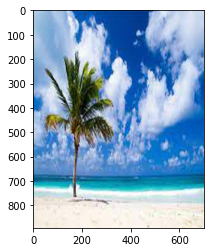

In [388]:
resize_image(img_path_b, img_path_b, 700, 892)

img_orig_b = cv2.imread(img_path_b)

plt.imshow(cv2.cvtColor(img_orig_b, cv2.COLOR_BGR2RGB)) # 이미지 색상 채널을 변경 (BGR 형식을 RGB 형식으로 변경)
plt.show() # 저장된 데이터를 이미지의 형식으로 표시

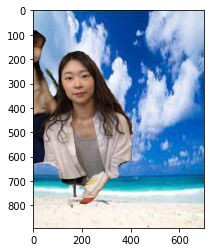

In [392]:
# np.where(조건, 참일때, 거짓일때)
# 세그멘테이션 마스크가 255인 부분만 원본 이미지 값을 가지고 오고 
# 아닌 영역은 블러된 이미지 값을 사용합니다.
img_concat4 = np.where(img_mask_color==255, img_orig3, img_orig_b)
# plt.imshow(): 저장된 데이터를 이미지의 형식으로 표시한다.
# cv2.cvtColor(입력 이미지, 색상 변환 코드): 입력 이미지의 색상 채널을 변경
# cv2.COLOR_BGR2RGB: 원본이 BGR 순서로 픽셀을 읽다보니 
# 이미지 색상 채널을 변경해야함 (BGR 형식을 RGB 형식으로 변경)
plt.imshow(cv2.cvtColor(img_concat4, cv2.COLOR_BGR2RGB))
plt.show()

ㅋㅋㅋㅋㅋㅋ 크로마키가 됐는데 허접하다 ㅋㅋㅋㅋㅋ